# Anomaly Detection Pipeline in Crypto Transactions

> **Disclaimer:** *UrbanStay Crypto Operations* is a hypothetical company used only to frame the problem. All data in this notebook is **synthetic**, so the reported metrics illustrate the methodology and are **not** a claim about performance on real blockchain data.

## Contents
1. [Project Goals & Tasks](#1.-Project-Goals-&-Tasks)
2. [Environment Setup & Dependencies](#2.-Environment-Setup-&-Dependencies)
3. [Data Generation & Exploratory Data Analysis (EDA)](#3.-Data-Generation-&-Exploratory-Data-Analysis-(EDA))
4. [Statistical Baselines (IQR & Robust Mahalanobis Distance)](#4.-Statistical-Baselines-(IQR-&-Robust-Mahalanobis-Distance))
5. [Unsupervised ML Models (Isolation Forest & DBSCAN)](#5.-Unsupervised-ML-Models-(Isolation-Forest-&-DBSCAN))
6. [Explainability with SHAP](#6.-Explainability-with-SHAP)
7. [Model Serving (FastAPI & Docker)](#7.-Model-Serving-(FastAPI-&-Docker))
8. [Results Summary, Limitations & Next Steps](#8.-Results-Summary,-Limitations-&-Next-Steps)

---

## 1. Project Goals & Tasks

**Business context (hypothetical).** A payment platform that accepts cryptocurrency needs to screen incoming transactions. Exploit-like activity (bursts of transfers, large amounts, unusual fees) must be caught, but analysts should not be flooded with alerts for legitimate large transfers ("whales").

**Objective.** Build and compare anomaly detectors that find exploit-like transactions with few false alarms, explain their decisions, and expose the best model as a small scoring service.

**Tasks**
1. Generate a synthetic transaction ledger with three segments: normal traffic, legitimate whale transfers, and exploit-like anomalies.
2. Explore the data (distributions, correlations, overlap between segments).
3. Build two statistical baselines: a univariate IQR rule and a robust Mahalanobis distance (Minimum Covariance Determinant).
4. Build two unsupervised ML models: Isolation Forest and DBSCAN.
5. Explain Isolation Forest decisions with SHAP.
6. Package the model as a FastAPI service with a Dockerfile and measure scoring latency.
7. Summarize results against the KPIs below and state the limitations.

**KPIs**

| KPI | Target |
|---|---|
| Recall on exploit-like transactions (held-out test set) | ≥ 95% |
| False-positive reduction vs. the IQR rule | ≥ 70% |
| Scoring latency (model only, excluding network) | ≤ 5 ms per transaction |

### Evaluation protocol

- The data is split once into a stratified **70% train / 30% test** set.
- All models are fitted **without labels** on the training data. Labels are used **only** to compute evaluation metrics.
- Isolation Forest is operated with an **alert budget of 2%** of transactions. This is a business assumption and is deliberately *not* equal to the true anomaly rate (1.5%). A sensitivity table shows how the result changes with the budget, and ROC-AUC / PR-AUC are reported because they do not depend on a threshold.
- DBSCAN has no `predict` method for new points, so it is fitted directly on the test set (a transductive setting).
- Results come from a single synthetic dataset and a single random seed.

[Back to contents](#Contents)

## 2. Environment Setup & Dependencies

**Plan:** import the required libraries, set plotting defaults, and fix random seeds for reproducibility. Dependencies are listed in `requirements.txt`.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy.stats import chi2
from sklearn.cluster import DBSCAN
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # global seed; every model below also receives random_state explicitly

%matplotlib inline
sns.set_style("darkgrid")
plt.rcParams.update({"figure.figsize": (14, 5), "font.size": 12, "axes.labelsize": 12})

display(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | scikit-learn {sklearn.__version__}")
display(f"Random seed fixed at {RANDOM_STATE}")

'numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1'

'Random seed fixed at 42'

**Result:** all libraries were imported and the random seed is fixed. Library versions are printed above for reproducibility.

[Back to contents](#contents)

## 3. Data Generation & Exploratory Data Analysis (EDA)

**Plan:** simulate a ledger with three segments and check how well they can be told apart.

| Segment | Description |
|---|---|
| `normal` | Everyday transfers: small log-normal amounts, low hourly velocity |
| `whale` | **Legitimate** large transfers: high amounts but normal velocity |
| `exploit` | Anomalies: large and variable amounts and high fees relative to amount. 70% are *bursts* (high velocity); 30% are *low-and-slow* (normal velocity) |

`gas_fee_usd` is generated as a fraction of `tx_amount_usd`, so these two features are strongly correlated **by construction**. Exploit parameters are chosen so that segments partly overlap; the simulation is a simplified stand-in for real fraud patterns.

In [2]:
FEATURES = ["tx_amount_usd", "gas_fee_usd", "tx_velocity_1h"]


def generate_blockchain_ledger(n_samples=10_000, exploit_rate=0.015, whale_rate=0.02, seed=RANDOM_STATE):
    # Synthetic ledger: normal traffic, legitimate whale transfers, exploit-like anomalies
    rng = np.random.default_rng(seed)
    n_exploit = int(n_samples * exploit_rate)
    n_whale = int(n_samples * whale_rate)
    n_normal = n_samples - n_exploit - n_whale

    def segment(n, amount_mu, amount_sigma, fee_lo, fee_hi, velocity_lam, label, name):
        amount = rng.lognormal(amount_mu, amount_sigma, n)
        return pd.DataFrame({
            "tx_amount_usd": amount,
            "gas_fee_usd": amount * rng.uniform(fee_lo, fee_hi, n),
            "tx_velocity_1h": rng.poisson(velocity_lam, n) + 1,  # scalar or per-row rate
            "is_anomaly": label,
            "segment": name,
        })

    # 70% of exploits are bursts (high velocity); 30% are "low-and-slow" (normal velocity, abnormal fees)
    exploit_velocity = np.where(rng.random(n_exploit) < 0.7, 20, 3)
    parts = [
        segment(n_normal, 3.0, 0.6, 0.0008, 0.003, 2, 0, "normal"),
        segment(n_whale, 6.0, 0.5, 0.0008, 0.003, 2, 0, "whale"),
        segment(n_exploit, 6.5, 1.0, 0.01, 0.06, exploit_velocity, 1, "exploit"),
    ]
    ledger = pd.concat(parts, ignore_index=True)
    return ledger.sample(frac=1, random_state=seed).reset_index(drop=True)


df_crypto = generate_blockchain_ledger()

dataset_summary = pd.DataFrame({
    "Metric": ["Transactions", "Features", "Exploit-like (anomaly) share", "Whale share (legitimate)", "Missing values"],
    "Value": [f"{len(df_crypto):,}", len(FEATURES),
              f"{df_crypto['is_anomaly'].mean():.2%}",
              f"{(df_crypto['segment'] == 'whale').mean():.2%}",
              int(df_crypto[FEATURES].isna().sum().sum())],
})
display(dataset_summary)
df_crypto.head()

,Metric,Value
0,Transactions,"10,000"
1,Features,3
2,Exploit-like (anomaly) share,1.50%
3,Whale share (legitimate),2.00%
4,Missing values,0


,tx_amount_usd,gas_fee_usd,tx_velocity_1h,is_anomaly,segment
0,38.483842,0.099180,1,0,normal
1,10.459375,0.012625,4,0,normal
2,7.571183,0.013210,1,0,normal
3,28.095855,0.066271,8,0,normal
4,12.525904,0.018123,2,0,normal


In [3]:
# Median feature values per segment
display(df_crypto.groupby("segment")[FEATURES].median().round(3))

# Stratified train/test split (labels are used only to stratify and, later, to evaluate)
train_df, test_df = train_test_split(df_crypto, test_size=0.3, stratify=df_crypto["is_anomaly"],
                                     random_state=RANDOM_STATE)
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_test = test_df["is_anomaly"].to_numpy()
print(f"Train: {len(train_df):,} rows | Test: {len(test_df):,} rows | Anomalies in test set: {int(y_test.sum())}")

,tx_amount_usd,gas_fee_usd,tx_velocity_1h
segment,,,
exploit,573.337,19.529,18.5
normal,19.952,0.036,3.0
whale,398.157,0.677,3.0


Train: 7,000 rows | Test: 3,000 rows | Anomalies in test set: 45


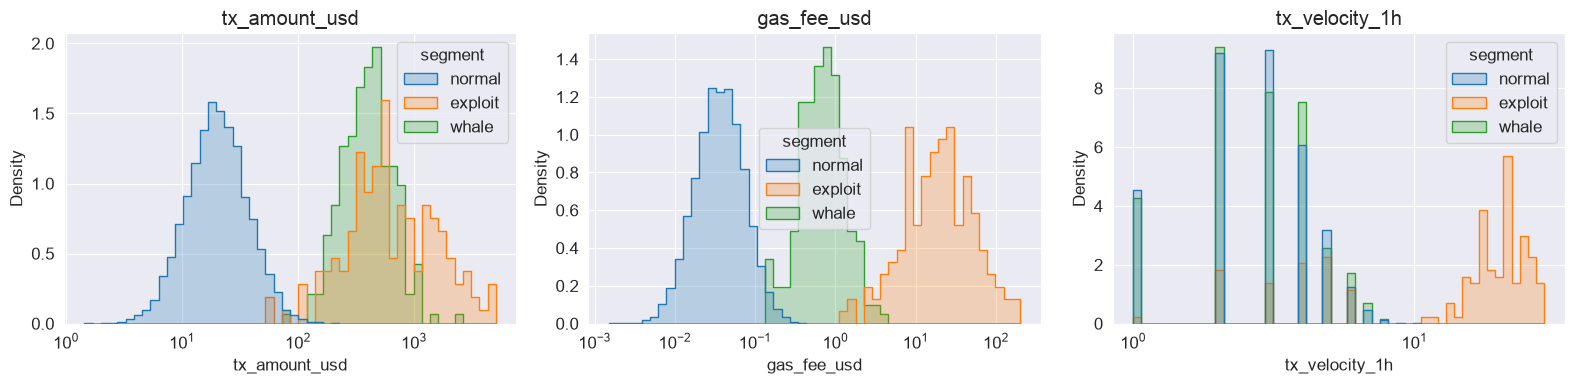

In [4]:
# Feature distributions by segment (log-scaled x axis)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, FEATURES):
    sns.histplot(data=df_crypto, x=col, hue="segment", log_scale=True, element="step",
                 stat="density", common_norm=False, bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

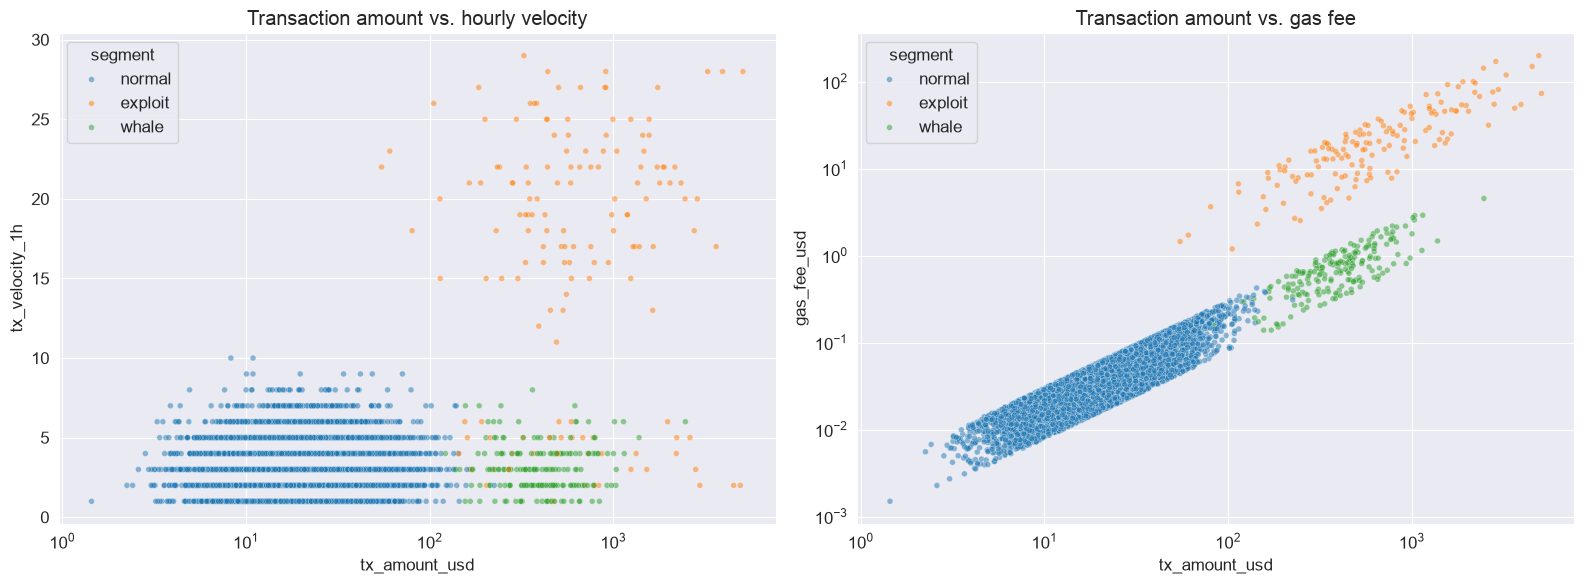

Correlation of log-features (normal + whale traffic only):


,tx_amount_usd,gas_fee_usd,tx_velocity_1h
tx_amount_usd,1.00,0.75,0.01
gas_fee_usd,0.75,1.00,0.01
tx_velocity_1h,0.01,0.01,1.00


In [5]:
# Where do the segments overlap?
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df_crypto, x="tx_amount_usd", y="tx_velocity_1h", hue="segment", alpha=0.5, s=18, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Transaction amount vs. hourly velocity")
sns.scatterplot(data=df_crypto, x="tx_amount_usd", y="gas_fee_usd", hue="segment", alpha=0.5, s=18, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Transaction amount vs. gas fee")
plt.tight_layout()
plt.show()

print("Correlation of log-features (normal + whale traffic only):")
legit = df_crypto[df_crypto["is_anomaly"] == 0]
display(np.log1p(legit[FEATURES]).corr().round(2))

**EDA summary**

- `tx_amount_usd` and `gas_fee_usd` are heavy-tailed and roughly log-normal, which is why the distance-based methods below work on log-transformed features.
- Whale transfers have amounts in the same range as many exploit transactions, so **amount alone cannot separate legitimate whales from exploits**; hourly velocity adds the missing information.
- Hourly velocity separates the *burst* exploits, but the *low-and-slow* exploits (about a third) have normal velocity. They stand out only through their fee relative to the amount, which is visible in the amount-vs-fee plot, so no single feature is sufficient.
- A rule that flags every large amount will produce many false alarms on whales.
- Fees correlate with amounts in legitimate traffic by construction, so the features are not independent.

[Back to contents](#Contents)

## 4. Statistical Baselines (IQR & Robust Mahalanobis Distance)

**Plan:** implement two classical baselines on the training data, without labels, and evaluate them on the test set.

1. **Univariate IQR rule:** flag a transaction if *any* feature lies outside the Tukey fences `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` computed on the training data. This is the reference for the false-positive-reduction KPI.
2. **Robust Mahalanobis distance:** estimate location and covariance of the log-transformed features with the Minimum Covariance Determinant (`MinCovDet`), which tolerates contamination without using labels. A transaction is flagged if its squared distance exceeds the 99.9% quantile of a χ² distribution with 3 degrees of freedom.

In [6]:
results = []        # one row of metrics per model
segment_rates = {}  # share of each segment flagged by each model


def report(name, y_pred, y_true=y_test, segments=test_df["segment"]):
    # Store precision/recall/F1 and the flag rate per segment for one model
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    results.append({
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "False positives": int(fp),
        "False negatives": int(fn),
    })
    segment_rates[name] = pd.Series(y_pred, index=segments.index).groupby(segments).mean()
    return pd.DataFrame([results[-1]]).set_index("Model").round(3)


# --- Baseline 1: univariate IQR rule (fences from training data) ---
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
outside = (X_test < q1 - 1.5 * iqr) | (X_test > q3 + 1.5 * iqr)
pred_iqr = outside.any(axis=1).astype(int).to_numpy()
display(report("IQR rule", pred_iqr))

,Precision,Recall,F1,False positives,False negatives
Model,,,,,
IQR rule,0.158,1.0,0.274,239,0


In [7]:
# --- Baseline 2: robust Mahalanobis distance (MinCovDet on log-features, no labels) ---
log_train, log_test = np.log1p(X_train.to_numpy()), np.log1p(X_test.to_numpy())

mcd = MinCovDet(random_state=RANDOM_STATE).fit(log_train)
squared_distance = mcd.mahalanobis(log_test)               # squared Mahalanobis distances
cutoff = chi2.ppf(0.999, df=len(FEATURES))                 # 99.9% quantile of chi-square(3)
pred_mahalanobis = (squared_distance > cutoff).astype(int)
display(report("Robust Mahalanobis (MCD)", pred_mahalanobis))

print("Share of each segment flagged:")
display(pd.DataFrame(segment_rates).round(3))

,Precision,Recall,F1,False positives,False negatives
Model,,,,,
Robust Mahalanobis (MCD),0.173,1.0,0.295,215,0


Share of each segment flagged:


,IQR rule,Robust Mahalanobis (MCD)
segment,,
exploit,1.00,1.000
normal,0.06,0.052
whale,1.00,1.000


**Observations**

- Both baselines catch (almost) every exploit-like transaction, but they also flag the legitimate whale transfers, because whales are statistical outliers in amount. The table above shows the flag rate per segment.
- The robust Mahalanobis distance considers the correlation between features, which removes some false alarms on normal traffic compared with the IQR rule, but it still cannot recognise that a large amount with normal velocity is legitimate.
- Both baselines have low precision in this setup, which is the motivation for the multivariate ML models in the next section.

[Back to contents](#Contents)

## 5. Unsupervised ML Models (Isolation Forest & DBSCAN)

**Plan**

- **Isolation Forest** is fitted on the raw training features (tree-based splits are not affected by feature scale). The decision threshold is set by an alert budget of 2%.
- **DBSCAN** works on distances, so features are log-transformed and standardized (scaler fitted on the training data). `eps` is read from a k-distance plot, and its sensitivity is shown explicitly.

In [8]:
ALERT_BUDGET = 0.02  # assumed share of transactions analysts can review (not the true anomaly rate)

forest_engine = IsolationForest(n_estimators=100, contamination=ALERT_BUDGET,
                                random_state=RANDOM_STATE, n_jobs=-1).fit(X_train)

pred_iforest = (forest_engine.predict(X_test) == -1).astype(int)
display(report("Isolation Forest", pred_iforest))

# Threshold-free quality: higher score = more anomalous
test_scores = -forest_engine.score_samples(X_test)
print(f"ROC-AUC: {roc_auc_score(y_test, test_scores):.3f} | PR-AUC: {average_precision_score(y_test, test_scores):.3f}")

# Sensitivity to the alert budget (thresholds taken from training-set scores)
train_scores = -forest_engine.score_samples(X_train)
rows = []
for budget in [0.005, 0.01, 0.015, 0.02, 0.03, 0.05]:
    flagged = test_scores > np.quantile(train_scores, 1 - budget)
    rows.append({"Alert budget": f"{budget:.1%}",
                 "Precision": precision_score(y_test, flagged, zero_division=0),
                 "Recall": recall_score(y_test, flagged),
                 "False positives": int((flagged & (y_test == 0)).sum())})
display(pd.DataFrame(rows).set_index("Alert budget").round(3))

,Precision,Recall,F1,False positives,False negatives
Model,,,,,
Isolation Forest,0.833,1.0,0.909,9,0


ROC-AUC: 1.000 | PR-AUC: 0.982


,Precision,Recall,False positives
Alert budget,,,
0.5%,1.000,0.244,0
1.0%,1.000,0.756,0
1.5%,0.872,0.911,6
2.0%,0.833,1.000,9
3.0%,0.479,1.000,49
5.0%,0.308,1.000,101


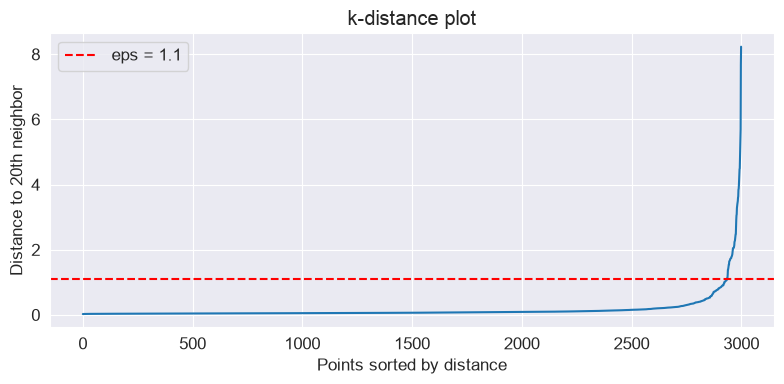

,Precision,Recall,F1,False positives,False negatives
Model,,,,,
DBSCAN,0.865,1.0,0.928,7,0


,Precision,Recall,False positives
eps,,,
0.7,0.409,1.0,65
0.9,0.750,1.0,15
1.1,0.865,1.0,7
1.3,0.938,1.0,3


Share of each segment flagged:


,IQR rule,Robust Mahalanobis (MCD),Isolation Forest,DBSCAN
segment,,,,
exploit,1.00,1.000,1.000,1.000
normal,0.06,0.052,0.000,0.000
whale,1.00,1.000,0.138,0.108


In [9]:
# --- DBSCAN on log-transformed, standardized features (fitted on the test set; transductive) ---
scaler = StandardScaler().fit(log_train)
Z_test = scaler.transform(log_test)

MIN_SAMPLES = 20
neighbor_dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z_test).kneighbors(Z_test)
k_distance = np.sort(neighbor_dist[:, -1])

EPS = 1.1  # chosen near the knee of the k-distance curve
plt.figure(figsize=(8, 4))
plt.plot(k_distance)
plt.axhline(EPS, color="red", linestyle="--", label=f"eps = {EPS}")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {MIN_SAMPLES}th neighbor")
plt.title("k-distance plot")
plt.legend()
plt.tight_layout()
plt.show()

pred_dbscan = (DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Z_test) == -1).astype(int)
display(report("DBSCAN", pred_dbscan))

# Sensitivity to eps
rows = []
for eps in [0.7, 0.9, 1.1, 1.3]:
    flagged = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Z_test) == -1
    rows.append({"eps": eps,
                 "Precision": precision_score(y_test, flagged, zero_division=0),
                 "Recall": recall_score(y_test, flagged),
                 "False positives": int((flagged & (y_test == 0)).sum())})
display(pd.DataFrame(rows).set_index("eps").round(3))

print("Share of each segment flagged:")
display(pd.DataFrame(segment_rates).round(3))

**Observations**

- Isolation Forest flags far fewer legitimate transactions than the two statistical baselines because it combines velocity, amount and fees. At the 2% alert budget, the remaining false positives are whale transfers.
- The alert budget is a precision/recall dial: a smaller budget gives cleaner alerts but misses more exploits, a larger one catches everything at the cost of more whale alerts. The sensitivity table makes this trade-off explicit.
- In this run DBSCAN is on par with Isolation Forest (the difference of a few false positives is within noise for 45 test anomalies). However, its quality swings widely with `eps` (see the sensitivity table), and good `eps` values are hard to pick without labels. The `eps` used here was chosen from the k-distance plot, and the sweep shows that other values would look better or much worse. DBSCAN also cannot score a new transaction without re-running on the data, which makes it unsuitable for the real-time service in Section 7.

[Back to contents](#Contents)

## 6. Explainability with SHAP

**Plan:** use `shap.TreeExplainer` (exact and fast for tree ensembles, and it explains the model's continuous anomaly output rather than the ±1 label) on a random sample of 50 exploit-like transactions from the test set. The table and plot below show which features drive the model's decisions. Only the **magnitude** of attributions is interpreted in the table.

shap 0.54.1


,mean |SHAP|
gas_fee_usd,4.4609
tx_amount_usd,3.7317
tx_velocity_1h,2.6355


/var/folders/k8/wwq1d9y57bv1f2h6ggxqtts00000gn/T/ipykernel_4222/1615206122.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, exploit_sample, show=False)


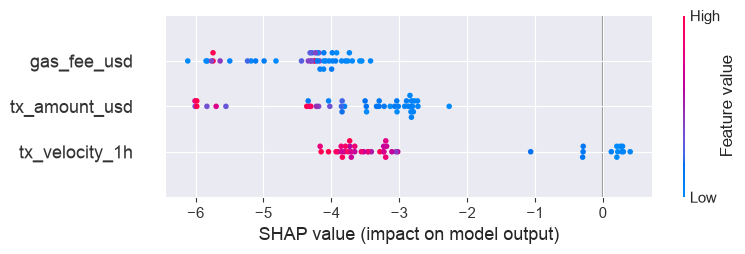

In [10]:
import shap

print(f"shap {shap.__version__}")
explainer = shap.TreeExplainer(forest_engine)

exploit_sample = X_test[y_test == 1].sample(n=min(50, int(y_test.sum())), random_state=RANDOM_STATE)
shap_values = explainer.shap_values(exploit_sample)

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
display(mean_abs_shap.rename("mean |SHAP|").to_frame().round(4))

shap.summary_plot(shap_values, exploit_sample, show=False)
plt.tight_layout()
plt.show()

**How to read the output**

- The table ranks features by their average absolute contribution to the isolation scores of the sampled exploit-like transactions.
- Because `gas_fee_usd` is generated from `tx_amount_usd`, these two features carry overlapping information, so attribution may be shared between them. Treat the ranking as descriptive of this synthetic dataset, not as a causal statement.
- SHAP gives analysts a feature-level explanation for a flagged transaction. It supports manual review but does not by itself make a system compliant with any regulation.

[Back to contents](#Contents)

## 7. Model Serving (FastAPI & Docker)

**Plan**

1. Save the trained Isolation Forest and write the service files (`main.py`, `requirements.txt`, `Dockerfile`) to the `api/` folder.
2. Smoke-test the scoring logic locally.
3. Measure scoring latency against the 5 ms KPI.

Design choices: the endpoint is a plain `def` (scikit-learn is CPU-bound and would block an async event loop), the model is loaded once at start-up, and suspicious transactions are routed to **manual review** instead of being blocked automatically.

In [11]:
import sys
from pathlib import Path

import joblib

API_DIR = Path("api")
API_DIR.mkdir(exist_ok=True)

forest_engine.set_params(n_jobs=1)  # single-row scoring does not benefit from parallelism
joblib.dump(forest_engine, API_DIR / "isolation_forest.joblib")

MAIN_PY = '''# Crypto transaction scoring service (Isolation Forest)
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

FEATURES = ["tx_amount_usd", "gas_fee_usd", "tx_velocity_1h"]
model = joblib.load(Path(__file__).parent / "isolation_forest.joblib")

app = FastAPI(title="Crypto Transaction Scoring API", version="1.0.0")


class Transaction(BaseModel):
    tx_amount_usd: float = Field(..., ge=0, examples=[12500.50])
    gas_fee_usd: float = Field(..., ge=0, examples=[45.20])
    tx_velocity_1h: int = Field(..., ge=0, examples=[4])


class Verdict(BaseModel):
    anomaly_score: float  # higher = more anomalous
    anomaly_detected: bool
    routing_action: str   # APPROVE or MANUAL_REVIEW


@app.get("/health")
def health():
    return {"status": "ok"}


# Plain `def`: FastAPI runs it in a worker thread, so CPU-bound scoring does not block the event loop
@app.post("/api/v1/score", response_model=Verdict)
def score(tx: Transaction) -> Verdict:
    X = pd.DataFrame([tx.model_dump()])[FEATURES]
    raw = float(model.score_samples(X)[0])
    flagged = raw < model.offset_  # same rule as model.predict(X) == -1
    return Verdict(anomaly_score=-raw,
                   anomaly_detected=bool(flagged),
                   routing_action="MANUAL_REVIEW" if flagged else "APPROVE")
'''

REQUIREMENTS_TXT = f'''fastapi>=0.110
uvicorn[standard]>=0.29
pydantic>=2.0
scikit-learn=={sklearn.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
joblib=={joblib.__version__}
'''

DOCKERFILE = f'''FROM python:{sys.version_info.major}.{sys.version_info.minor}-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY main.py isolation_forest.joblib ./
RUN useradd --create-home appuser
USER appuser
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=3s CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "2"]
'''

(API_DIR / "main.py").write_text(MAIN_PY)
(API_DIR / "requirements.txt").write_text(REQUIREMENTS_TXT)
(API_DIR / "Dockerfile").write_text(DOCKERFILE)

for name, body, lang in [("api/main.py", MAIN_PY, "python"), ("api/Dockerfile", DOCKERFILE, "dockerfile")]:
    display(Markdown(f"**{name}**\n\n```{lang}\n{body}\n```"))
print("Written:", ", ".join(sorted(p.name for p in API_DIR.iterdir())))

**api/main.py**

```python
# Crypto transaction scoring service (Isolation Forest)
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

FEATURES = ["tx_amount_usd", "gas_fee_usd", "tx_velocity_1h"]
model = joblib.load(Path(__file__).parent / "isolation_forest.joblib")

app = FastAPI(title="Crypto Transaction Scoring API", version="1.0.0")


class Transaction(BaseModel):
    tx_amount_usd: float = Field(..., ge=0, examples=[12500.50])
    gas_fee_usd: float = Field(..., ge=0, examples=[45.20])
    tx_velocity_1h: int = Field(..., ge=0, examples=[4])


class Verdict(BaseModel):
    anomaly_score: float  # higher = more anomalous
    anomaly_detected: bool
    routing_action: str   # APPROVE or MANUAL_REVIEW


@app.get("/health")
def health():
    return {"status": "ok"}


# Plain `def`: FastAPI runs it in a worker thread, so CPU-bound scoring does not block the event loop
@app.post("/api/v1/score", response_model=Verdict)
def score(tx: Transaction) -> Verdict:
    X = pd.DataFrame([tx.model_dump()])[FEATURES]
    raw = float(model.score_samples(X)[0])
    flagged = raw < model.offset_  # same rule as model.predict(X) == -1
    return Verdict(anomaly_score=-raw,
                   anomaly_detected=bool(flagged),
                   routing_action="MANUAL_REVIEW" if flagged else "APPROVE")

```

**api/Dockerfile**

```dockerfile
FROM python:3.14-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY main.py isolation_forest.joblib ./
RUN useradd --create-home appuser
USER appuser
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=3s CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "2"]

```

Written: .DS_Store, Dockerfile, gitignore, isolation_forest.joblib, main.py, requirements.txt


In [12]:
# Smoke test: mirrors the endpoint logic (the HTTP layer itself is not tested here)
served_model = joblib.load(API_DIR / "isolation_forest.joblib")


def score_transaction(payload):
    X = pd.DataFrame([payload])[FEATURES]
    raw = float(served_model.score_samples(X)[0])
    flagged = raw < served_model.offset_
    return {"anomaly_score": round(-raw, 4), "anomaly_detected": bool(flagged),
            "routing_action": "MANUAL_REVIEW" if flagged else "APPROVE"}


samples = {
    "typical transfer": {"tx_amount_usd": 20.0, "gas_fee_usd": 0.04, "tx_velocity_1h": 3},
    "burst of large transfers": {"tx_amount_usd": 900.0, "gas_fee_usd": 25.0, "tx_velocity_1h": 22},
}
for label, payload in samples.items():
    print(f"{label:26s}", score_transaction(payload))

# The single-call rule must agree with model.predict on the whole test set
rule_flags = served_model.score_samples(X_test) < served_model.offset_
assert (rule_flags == (served_model.predict(X_test) == -1)).all()
print("Offset rule matches model.predict on the test set.")

typical transfer           {'anomaly_score': 0.3514, 'anomaly_detected': False, 'routing_action': 'APPROVE'}
burst of large transfers   {'anomaly_score': 0.841, 'anomaly_detected': True, 'routing_action': 'MANUAL_REVIEW'}
Offset rule matches model.predict on the test set.


In [13]:
import time

payload = {"tx_amount_usd": 150.0, "gas_fee_usd": 2.5, "tx_velocity_1h": 6}
for _ in range(20):                      # warm-up
    score_transaction(payload)

timings = []
for _ in range(300):
    start = time.perf_counter()
    score_transaction(payload)
    timings.append((time.perf_counter() - start) * 1000)
latency_p50, latency_p95 = np.percentile(timings, [50, 95])

batch = X_test.iloc[:100]
start = time.perf_counter()
served_model.score_samples(batch)
batch_per_tx = (time.perf_counter() - start) * 1000 / len(batch)

LATENCY_BUDGET_MS = 5.0
print(f"Single request (model only): p50 = {latency_p50:.2f} ms | p95 = {latency_p95:.2f} ms")
print(f"Micro-batch of {len(batch)}: {batch_per_tx:.3f} ms per transaction")
print(f"Budget {LATENCY_BUDGET_MS} ms for single requests: {'met' if latency_p95 <= LATENCY_BUDGET_MS else 'NOT met'} (p95)")

Single request (model only): p50 = 1.86 ms | p95 = 2.32 ms
Micro-batch of 100: 0.021 ms per transaction
Budget 5.0 ms for single requests: met (p95)


**Notes**

- Latency depends on the hardware and library versions; re-run the cell above on your own machine. The measurement covers feature preparation and model scoring only, not HTTP or network overhead.
- scikit-learn has a fixed per-call overhead, so single-request latency can exceed the budget even for a small model. If the budget is not met, options are fewer trees, micro-batching requests, or exporting the model to a lighter runtime.
- `api/requirements.txt` pins the scikit-learn, pandas, numpy and joblib versions used to create the model file, because pickled models are version-sensitive. The Dockerfile uses the same Python version as this notebook.
- The Dockerfile and the HTTP endpoint are provided as a reference implementation. They were **not** built, deployed or load-tested in this notebook.

[Back to contents](#Contents)

## 8. Results Summary, Limitations & Next Steps

**Plan:** collect all metrics computed above into one table, check the KPIs, and state what the results do and do not show.

In [14]:
summary_table = pd.DataFrame(results).set_index("Model").round(3)
display(summary_table)

print("Share of each segment flagged (test set):")
display(pd.DataFrame(segment_rates).round(3))

# KPI check, computed from the results above
iforest_row = summary_table.loc["Isolation Forest"]
iqr_fp = summary_table.loc["IQR rule", "False positives"]
fp_reduction = 1 - iforest_row["False positives"] / iqr_fp

kpi_table = pd.DataFrame([
    ("Recall on exploit-like transactions", ">= 95%", f"{iforest_row['Recall']:.1%}", iforest_row["Recall"] >= 0.95),
    ("False-positive reduction vs. IQR rule", ">= 70%", f"{fp_reduction:.1%}", fp_reduction >= 0.70),
    ("Scoring latency, single request (p95)", f"<= {LATENCY_BUDGET_MS:.0f} ms", f"{latency_p95:.2f} ms", latency_p95 <= LATENCY_BUDGET_MS),
], columns=["KPI", "Target", "Measured", "Met"])
kpi_table["Met"] = kpi_table["Met"].map({True: "yes", False: "no"})
display(kpi_table.set_index("KPI"))

,Precision,Recall,F1,False positives,False negatives
Model,,,,,
IQR rule,0.158,1.0,0.274,239,0
Robust Mahalanobis (MCD),0.173,1.0,0.295,215,0
Isolation Forest,0.833,1.0,0.909,9,0
DBSCAN,0.865,1.0,0.928,7,0


Share of each segment flagged (test set):


,IQR rule,Robust Mahalanobis (MCD),Isolation Forest,DBSCAN
segment,,,,
exploit,1.00,1.000,1.000,1.000
normal,0.06,0.052,0.000,0.000
whale,1.00,1.000,0.138,0.108


,Target,Measured,Met
KPI,,,
Recall on exploit-like transactions,>= 95%,100.0%,yes
False-positive reduction vs. IQR rule,>= 70%,96.2%,yes
"Scoring latency, single request (p95)",<= 5 ms,2.32 ms,yes


### Conclusions

- On this synthetic benchmark, the multivariate models (Isolation Forest, DBSCAN) separate exploit-like transactions from legitimate whale transfers much better than the statistical baselines, which flag every large transfer regardless of velocity or fee structure.
- Isolation Forest is chosen for deployment not because it scored best (DBSCAN is comparable here) but because it can score single transactions, and its operating point is controlled by an explicit alert budget.
- The KPI table above is computed from the run and is the authoritative statement of which targets were met; the latency KPI in particular depends on the hardware used.

### Limitations

- **Synthetic data:** the segments follow simple parametric distributions that were chosen by the author. Real fraud is adaptive, noisier and less separable, so real-world metrics will be lower.
- **Single dataset and seed:** no confidence intervals or repeated runs; small differences between models should not be over-interpreted (the test set has only a few dozen anomalies).
- **No temporal structure:** transactions are treated as independent and identically distributed; there is no time-based validation and no concept drift.
- **Simplified features:** velocity is given as an input, whereas in production it would be computed from a transaction stream.
- **Operating point:** the alert budget is an assumption; the cost of a missed exploit versus an unnecessary review has not been quantified.
- **Serving:** the API and Dockerfile are untested beyond a local smoke test of the scoring logic.

### Next steps

- Validate on a public labelled dataset (for example, the Elliptic Bitcoin dataset) and use time-based train/test splits.
- Repeat experiments over several seeds and report confidence intervals.
- Add drift monitoring and an analyst feedback loop for threshold calibration.
- Quantify business value with a simple cost model (review cost per alert versus loss per missed exploit).
- Build the Docker image, add API tests (for example with FastAPI's `TestClient`) and load-test the service.

[Back to contents](#Contents)